PCA reduction to 13 to 2 features

In [2]:
#AP24110010137
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [1]:
from google.colab import files

uploaded = files.upload()


Saving WineQT.csv to WineQT.csv


In [3]:
#AP24110010137
df = pd.read_csv("WineQT.csv")

print("Original dataset shape:", df.shape)
print("Total features:", df.shape[1])
print(df.head())


Original dataset shape: (1143, 13)
Total features: 13
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0     

In [4]:
#AP24110010137
X = df.copy()

print("Features before PCA:", X.shape[1])
print("Column names:", X.columns.tolist())


Features before PCA: 13
Column names: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']


In [9]:
#AP24110010137
scaler = StandardScaler()
X_pca = scaler.fit_transform(X)

print("Shape after scaling:", X_pca.shape)

Shape after scaling: (1143, 13)


In [10]:
#AP24110010137
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

print("Before PCA:", X.shape)
print("After PCA:", X_pca.shape)

print("Explained variance ratio:",
      pca.explained_variance_ratio_)

print("Total variance retained:",
      round(pca.explained_variance_ratio_.sum() * 100, 3), "%")


Before PCA: (1143, 13)
After PCA: (1143, 3)
Explained variance ratio: [9.94582078e-01 5.14068487e-03 2.47996601e-04]
Total variance retained: 99.997 %


In [11]:
#AP24110010137
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2" ,"PC3"]
)

print(pca_df.head())
print("Final dataset shape:", pca_df.shape)


          PC1        PC2       PC3
0 -804.862110 -18.239453  1.090984
1 -804.084622  17.024538  7.546480
2 -803.006496   2.161253  0.621675
3 -802.051454   8.426364  1.219193
4 -800.862238 -18.211546  1.076066
Final dataset shape: (1143, 3)


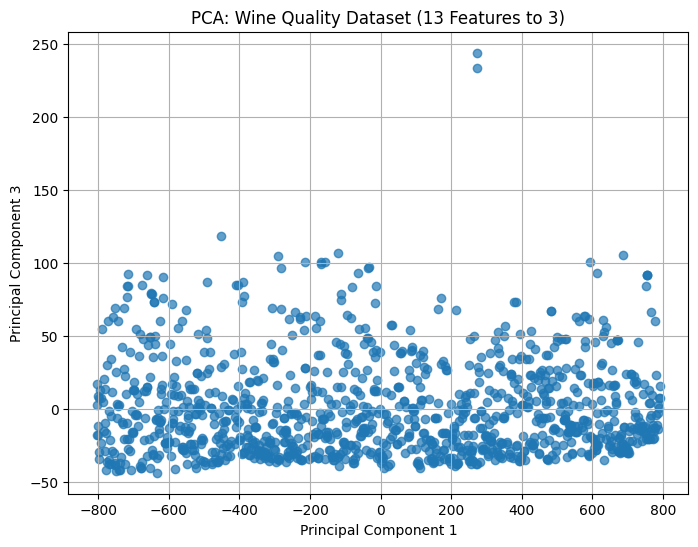

In [12]:
#AP24110010137
plt.figure(figsize=(8, 6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.ylabel("Principal Component 3")
plt.title("PCA: Wine Quality Dataset (13 Features to 3)")
plt.grid(True)
plt.show()


questions :
Question 1: What happens if we change the number of components?
1. Change PCA(n_components=2) to PCA(n_components=3).
 2. How many features are present after reduction?  
 ans : 3 features are present after reduction
 3. Does the number of samples change?  
 Does the total variance retained increase or decrease?  
ans : It increases or stays the same because adding a principal component captures additional variance.

Question 2 : What happens if standardization is removed?  
1. Replace X_scaled with X in the PCA transformation.  
Does the explained variance ratio change?
Ans : yes the variance ratio has changed   
2. Why might features with larger numerical scales influence PCA more strongly?
Sol : PCA maximizes variance. Features with larger numerical ranges or variances can dominate the calculation and influence the principal components more heavily.
 3. Is standardization always necessary?
 Sol : No. It is usually recommended when features use different units or scales.


Question 3 : What happens if we retain more components?  
Try 1, 2, 3, 5 and 10 principal components.  
1. How does the cumulative explained variance change?
Sol : It increases as more principal components are retained.
2. How many components are needed to retain at least 90% of the variance?
Sol : 9 components are needed to retain at least 90% of the variance  
3. Is reducing to two components always the best choice?  
Sol : No. Two components are useful for visualization, but more components may be needed to preserve information for analysis or prediction.

In [15]:
#AP24110010137
from sklearn.decomposition import PCA
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Re-scale the original 13 features to avoid using the 3-component overridden X_pca
scaler = StandardScaler()
X_scaled_full = scaler.fit_transform(X)

# Calculate all 13 principal components
pca_all = PCA()
pca_all.fit(X_scaled_full)

# Test different numbers of components
results = []

for n in [1, 2, 3, 5, 10]:
    pca = PCA(n_components=n)
    pca.fit(X_scaled_full)

    cumulative_variance = pca.explained_variance_ratio_.sum() * 100

    results.append({
        "Components": n,
        "Cumulative Variance (%)": round(cumulative_variance, 2)
    })

results_df = pd.DataFrame(results)
display(results_df)

# Find the minimum components needed for 90% variance
cumulative = pca_all.explained_variance_ratio_.cumsum()
components_90 = (cumulative >= 0.90).argmax() + 1

print("Components needed for 90% variance:", components_90)

,Components,Cumulative Variance (%)
0,1,25.19
1,2,42.82
2,3,55.91
3,5,72.71
4,10,95.85


Components needed for 90% variance: 9


QUESTION 4 : What happens to the visualization?  
Plot the first two principal components and observe the three wine classes.
 1. Are the classes clearly separated?  
2. What information might be lost when reducing 13 features to 2?
 3. Does PCA use the class labels to create the components?  


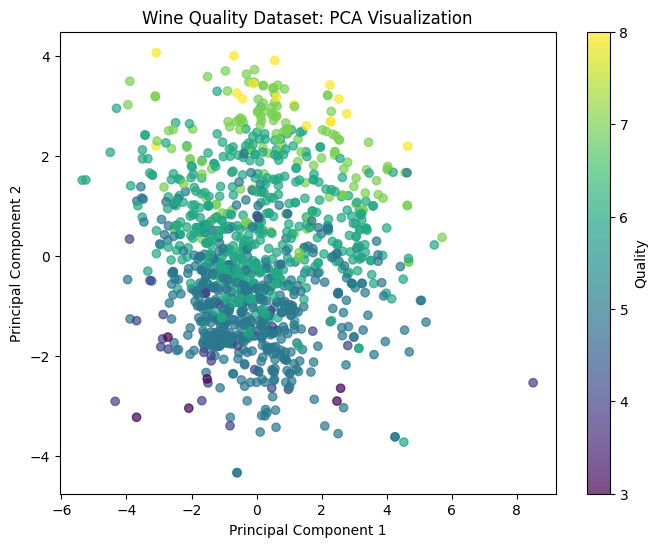

In [18]:
#AP24110010137
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled_full)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["quality"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Quality Dataset: PCA Visualization")
plt.colorbar(scatter, label="Quality")
plt.show()

1. Are the classes clearly separated?  
Sol : Not necessarily. Wine samples with different quality scores may overlap in the two-dimensional plot.
2. What information might be lost when reducing 13 features to 2?
Sol : Information represented by the discarded principal components, including differences between samples and variations in the original features.
 3. Does PCA use the class labels to create the components?
 Sol : PCA is inherently unsupervised and does not optimize components using class labels. However, in your current code, quality is included among the 13 input columns, so its numerical values influence the components. The color labels are also used to display quality in the plot.

Question 5 : Question 5: Does PCA select existing features?  
1. Are the two principal components original Wine dataset columns?  
Sol : No. PC1 and PC2 are new variables formed from weighted combinations of the original features.
2. What is the diƯerence between feature selection and feature extraction?
Sol : feature selection : Selects existing features.
feature reduction : Creates new features from existing ones.
3. Why is PCA considered a feature extraction technique?
Sol : Because it transforms the original features into new principal components that capture as much variance as possible, rather than simply selecting existing columns.
